# 03 - Time-series exploratory data analysis

This notebook studies the 12 product-store series selected in notebook 02. It uses training data only for its conclusions, leaving validation data available for model comparison and final-test data untouched.

The analysis covers demand profiles, recent histories, weekday patterns, autocorrelation, seven-day totals, and price completeness.

## 1. Load the prepared development data

Notebook 02 creates the metadata and joined development files. Loading these small files keeps the time-series analysis separate from raw-data preparation.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures" / "series_eda"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_END = 1885
VALIDATION_END = 1913
train_day_columns = [f"d_{day}" for day in range(1, TRAIN_END + 1)]
development_day_columns = [f"d_{day}" for day in range(1, VALIDATION_END + 1)]

selected_metrics = pd.read_csv(PROCESSED_DATA_DIR / "selected_series_metadata.csv")
development_long = pd.read_csv(
    PROCESSED_DATA_DIR / "selected_series_development.csv",
    parse_dates=["date"],
)

selected_sales = (
    development_long.pivot(index=["item_id", "store_id"], columns="d", values="sales")
    .reindex(columns=development_day_columns)
    .reset_index()
)

print(f"Selected series: {len(selected_metrics)}")
print(f"Development rows: {len(development_long):,}")
print(f"Available days: d_{development_long['day_number'].min()} to d_{development_long['day_number'].max()}")

assert len(selected_metrics) == 12
assert len(development_long) == 12 * VALIDATION_END
assert development_long["day_number"].max() == VALIDATION_END
assert development_long.duplicated(["item_id", "store_id", "date"]).sum() == 0

Selected series: 12
Development rows: 22,956
Available days: d_1 to d_1913


## 2. Training-period analysis

All plots and summary tables below use `d_1` through `d_1885`. Validation remains available for the forecasting stage without influencing these exploratory conclusions.

In [2]:
training_long = development_long[development_long["split"] == "train"].copy()

profile_summary = (
    selected_metrics.groupby("profile", observed=True)
    .agg(
        selected_series=("series_key", "nunique"),
        median_daily_mean=("mean_daily_sales", "median"),
        median_zero_share=("zero_sales_share", "median"),
        median_cv=("coefficient_of_variation", "median"),
        median_lag7_autocorrelation=("lag7_autocorrelation", "median"),
    )
    .reset_index()
)

display(profile_summary.round(3))

,profile,selected_series,median_daily_mean,median_zero_share,median_cv,median_lag7_autocorrelation
0,intermittent,3,0.134,0.900,3.343,0.149
1,stable,3,6.858,0.035,0.578,0.395
2,variable,3,0.919,0.585,2.655,0.071
3,weekly_pattern,3,7.016,0.191,1.046,0.663


### Profile inference

The profile summary checks whether the selection rules produced meaningfully different groups. Median zero-sales share should be highest for intermittent series. Median coefficient of variation should be highest for variable or intermittent series. The weekly-pattern group should have the strongest median lag-7 autocorrelation.

These differences matter for forecasting because one error measure or one uncertainty rule may behave differently for dense, seasonal, sparse, and highly variable demand.

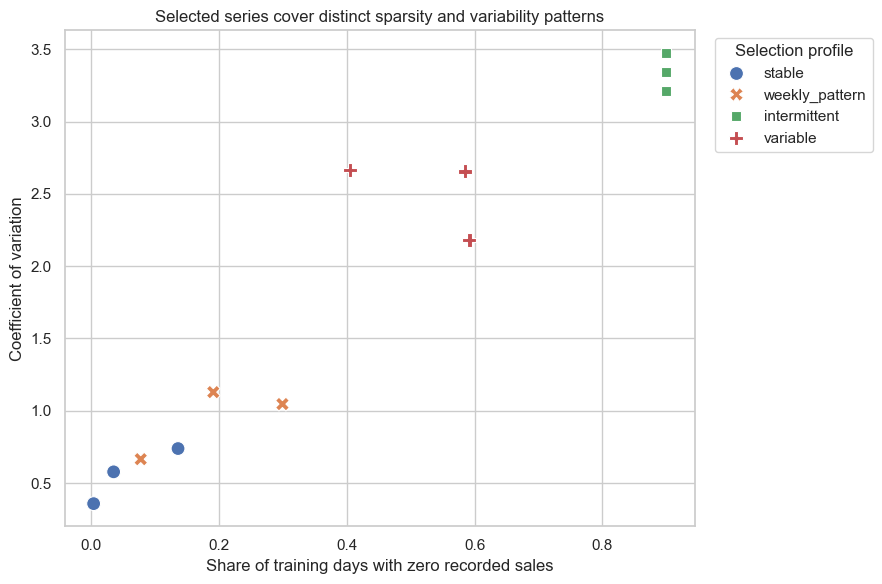

In [3]:
profile_order = ["stable", "weekly_pattern", "intermittent", "variable"]

fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(
    data=selected_metrics,
    x="zero_sales_share",
    y="coefficient_of_variation",
    hue="profile",
    style="profile",
    hue_order=profile_order,
    s=100,
    ax=ax,
)
ax.set(
    title="Selected series cover distinct sparsity and variability patterns",
    xlabel="Share of training days with zero recorded sales",
    ylabel="Coefficient of variation",
)
ax.legend(title="Selection profile", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
fig.savefig(FIGURE_DIR / "series_profile_map.png", dpi=300, bbox_inches="tight")
plt.show()

### Sparsity and variability inference

The profile map shows why the selected series should not share one forecasting assumption. Intermittent series have many zero-sales days, while variable series combine more frequent sales with large changes in volume. Stable series occupy the lower-variability area. This separation supports evaluating results by demand profile instead of reporting only one overall average.

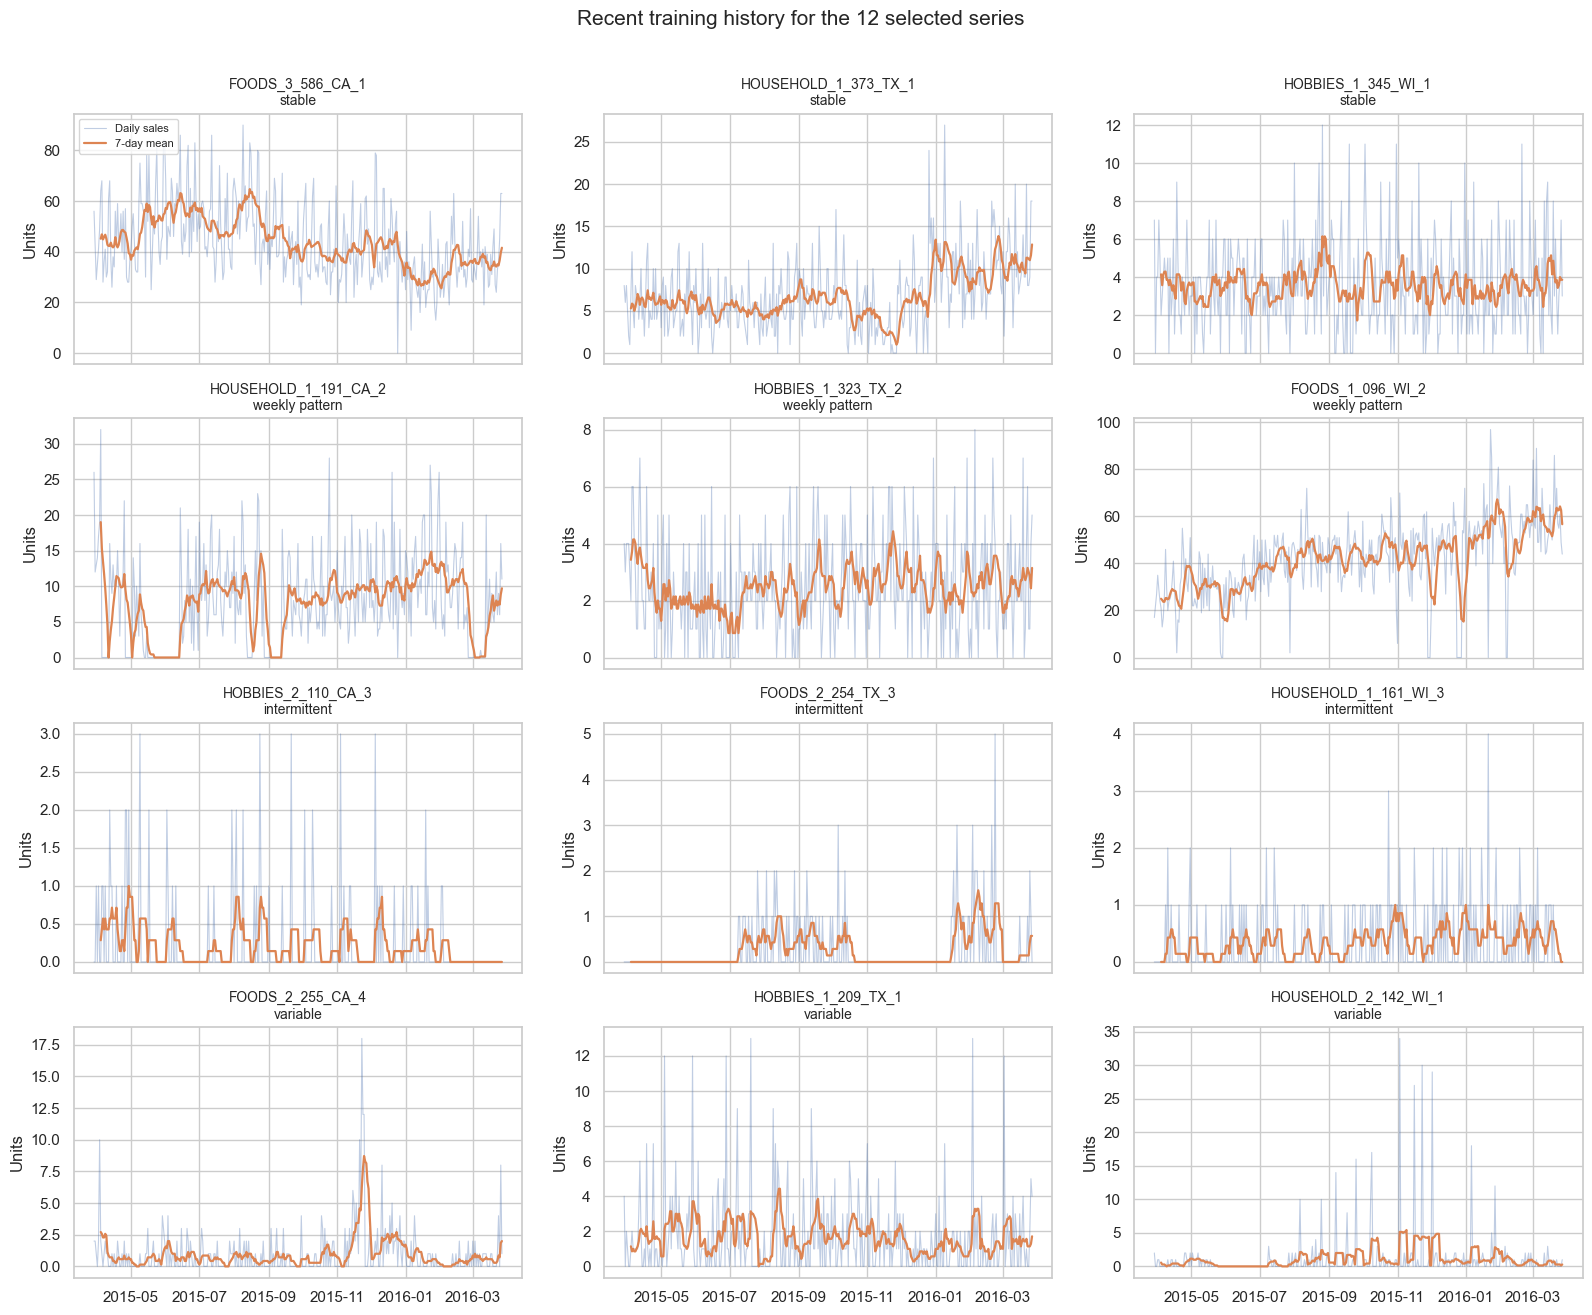

In [4]:
recent_training = training_long[training_long["day_number"] > TRAIN_END - 365].copy()

fig, axes = plt.subplots(4, 3, figsize=(16, 13), sharex=True)

for ax, series_key in zip(axes.flat, selected_metrics["series_key"]):
    series_data = recent_training[recent_training["series_key"] == series_key].sort_values("date")
    ax.plot(series_data["date"], series_data["sales"], alpha=0.35, linewidth=0.8, label="Daily sales")
    ax.plot(
        series_data["date"],
        series_data["sales"].rolling(7).mean(),
        linewidth=1.6,
        label="7-day mean",
    )
    profile = series_data["profile"].iat[0]
    ax.set_title(f"{series_key}\n{profile.replace('_', ' ')}", fontsize=10)
    ax.set_ylabel("Units")

axes[0, 0].legend(loc="upper left", fontsize=8)
fig.suptitle("Recent training history for the 12 selected series", fontsize=15, y=1.01)
plt.tight_layout()
fig.savefig(FIGURE_DIR / "recent_training_history.png", dpi=300, bbox_inches="tight")
plt.show()

### Time-series inference

The recent histories show how the profile measures appear in daily data. Stable series have more continuous sales, intermittent series contain long runs of zeros, and variable series contain larger spikes. Weekly-pattern series still change over time, so lag-7 correlation should be treated as one feature of their behavior rather than a complete description.

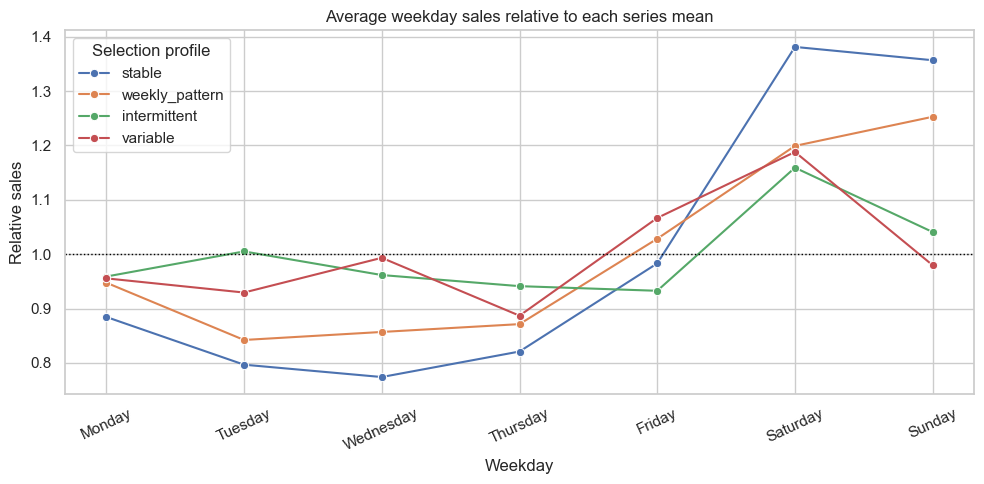

profile,intermittent,stable,variable,weekly_pattern
weekday,,,,
Monday,0.959,0.885,0.956,0.948
Tuesday,1.005,0.797,0.929,0.842
Wednesday,0.962,0.774,0.993,0.857
Thursday,0.941,0.821,0.887,0.871
Friday,0.933,0.983,1.067,1.028
Saturday,1.159,1.381,1.188,1.199
Sunday,1.041,1.357,0.980,1.253


In [5]:
series_training_mean = training_long.groupby("series_key", observed=True)["sales"].transform("mean")
training_long["sales_relative_to_series_mean"] = training_long["sales"] / series_training_mean

weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_pattern = (
    training_long.groupby(["profile", "weekday"], observed=True)["sales_relative_to_series_mean"]
    .mean()
    .reset_index()
)
weekday_pattern["weekday"] = pd.Categorical(
    weekday_pattern["weekday"], categories=weekday_order, ordered=True
)
weekday_pattern = weekday_pattern.sort_values(["profile", "weekday"])

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(
    data=weekday_pattern,
    x="weekday",
    y="sales_relative_to_series_mean",
    hue="profile",
    hue_order=profile_order,
    marker="o",
    ax=ax,
)
ax.axhline(1, color="black", linewidth=1, linestyle=":")
ax.set(
    title="Average weekday sales relative to each series mean",
    xlabel="Weekday",
    ylabel="Relative sales",
)
ax.tick_params(axis="x", rotation=25)
ax.legend(title="Selection profile")
plt.tight_layout()
fig.savefig(FIGURE_DIR / "weekday_pattern_by_profile.png", dpi=300, bbox_inches="tight")
plt.show()

display(weekday_pattern.pivot(index="weekday", columns="profile", values="sales_relative_to_series_mean").round(3))

### Weekday inference

Sales are divided by each series mean before profiles are combined. This prevents a high-volume item from dominating the group pattern. Values above 1 indicate a weekday with sales above that series' usual level. The chart describes repeated weekday differences, but it does not explain whether price, events, store operations, or customer behavior caused them.

In [6]:
autocorrelation_rows = []
selected_training_wide = selected_sales.set_index(
    selected_sales["item_id"].astype(str) + "_" + selected_sales["store_id"].astype(str)
)[train_day_columns]

for series_key, row in selected_training_wide.iterrows():
    values = row.to_numpy(dtype="float64")
    profile = selected_metrics.loc[selected_metrics["series_key"] == series_key, "profile"].iat[0]
    for lag in [1, 7, 14, 28]:
        correlation = np.corrcoef(values[:-lag], values[lag:])[0, 1]
        autocorrelation_rows.append(
            {"series_key": series_key, "profile": profile, "lag_days": lag, "autocorrelation": correlation}
        )

autocorrelation_table = pd.DataFrame(autocorrelation_rows)
autocorrelation_by_profile = autocorrelation_table.pivot_table(
    index="profile",
    columns="lag_days",
    values="autocorrelation",
    aggfunc="median",
).reindex(profile_order)

autocorrelation_by_profile.columns = [f"lag_{lag}" for lag in autocorrelation_by_profile.columns]
display(autocorrelation_by_profile.round(3))

,lag_1,lag_7,lag_14,lag_28
profile,,,,
stable,0.273,0.395,0.370,0.331
weekly_pattern,0.679,0.663,0.602,0.497
intermittent,0.085,0.149,0.116,0.084
variable,0.038,0.071,0.010,0.032


### Autocorrelation inference

Lag-1 correlation measures persistence from one day to the next. Lags 7, 14, and 28 check repeated weekly timing. The weekly-pattern group is expected to remain stronger at weekly lags. Positive autocorrelation supports models that use recent and seasonal lags, but model performance must still be measured on validation data.

,count,mean,median,std,max
profile,,,,,
stable,807,131.559998,48.0,139.47,597.0
weekly_pattern,807,61.250000,42.0,73.30,471.0
intermittent,807,0.940000,0.0,1.57,9.0
variable,807,9.240000,6.0,12.24,201.0


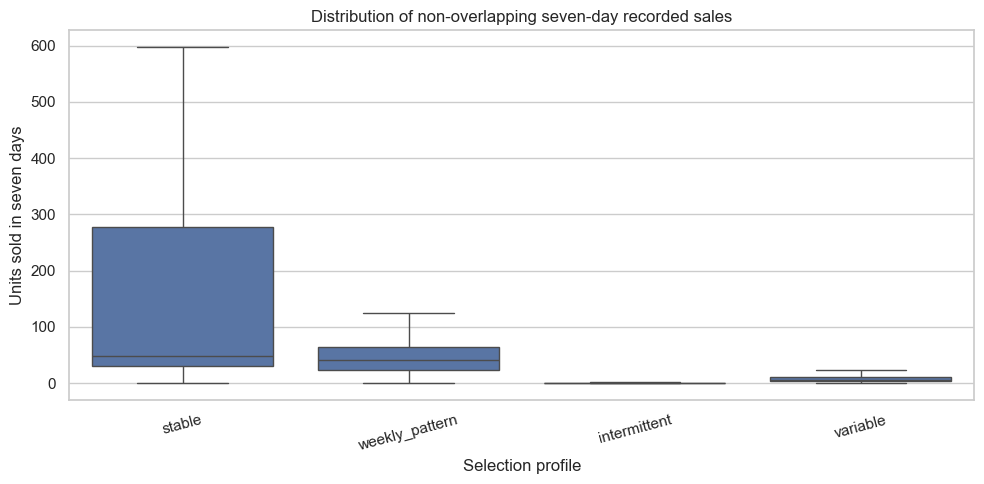

In [7]:
complete_training_weeks = TRAIN_END // 7
days_in_complete_weeks = complete_training_weeks * 7

weekly_sales_values = (
    selected_sales[train_day_columns[:days_in_complete_weeks]]
    .to_numpy(dtype="float32")
    .reshape(len(selected_sales), complete_training_weeks, 7)
    .sum(axis=2)
)

selected_sales_series_keys = (
    selected_sales["item_id"].astype(str) + "_" + selected_sales["store_id"].astype(str)
)
profile_by_series = selected_metrics.set_index("series_key")["profile"]
selected_sales_profiles = selected_sales_series_keys.map(profile_by_series)

assert selected_sales_profiles.notna().all()

weekly_demand = pd.DataFrame(
    {
        "series_key": np.repeat(selected_sales_series_keys.to_numpy(), complete_training_weeks),
        "profile": np.repeat(selected_sales_profiles.to_numpy(), complete_training_weeks),
        "week_number": np.tile(np.arange(1, complete_training_weeks + 1), len(selected_metrics)),
        "seven_day_sales": weekly_sales_values.reshape(-1),
    }
)

weekly_demand_summary = (
    weekly_demand.groupby("profile", observed=True)["seven_day_sales"]
    .agg(["count", "mean", "median", "std", "max"])
    .reindex(profile_order)
)
display(weekly_demand_summary.round(2))

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(
    data=weekly_demand,
    x="profile",
    y="seven_day_sales",
    order=profile_order,
    showfliers=False,
    ax=ax,
)
ax.set(
    title="Distribution of non-overlapping seven-day recorded sales",
    xlabel="Selection profile",
    ylabel="Units sold in seven days",
)
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
fig.savefig(FIGURE_DIR / "seven_day_demand_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

### Seven-day demand inference

Seven-day totals are useful because inventory decisions often cover more than one day. The distributions show how both the center and spread of weekly recorded sales differ by profile. The analysis does not yet assume a supplier lead time. Lead time, review frequency, and replenishment timing will be set before the inventory simulation.

In [8]:
training_long["missing_price"] = training_long["sell_price"].isna()
training_long["positive_sales_without_price"] = (
    training_long["sales"].gt(0) & training_long["missing_price"]
)

price_completeness = (
    training_long.groupby("profile", observed=True)
    .agg(
        rows=("sales", "size"),
        missing_price_rows=("missing_price", "sum"),
        positive_sales_without_price=("positive_sales_without_price", "sum"),
    )
    .reset_index()
)
price_completeness["missing_price_pct"] = (
    100 * price_completeness["missing_price_rows"] / price_completeness["rows"]
)

display(price_completeness.round(3))

,profile,rows,missing_price_rows,positive_sales_without_price,missing_price_pct
0,intermittent,5655,1778,0,31.441
1,stable,5655,0,0,0.000
2,variable,5655,231,0,4.085
3,weekly_pattern,5655,0,0,0.000


### Price-data inference

Missing prices can occur before an item appears in the price table. They should not be filled automatically because a missing pre-release price and an unexplained price gap have different meanings. Later models can use price only after checking the rows where positive sales have no matching price.

## 3. Conclusions and next step

The selected groups differ in sparsity, variation, weekly timing, and seven-day sales. Stable series sell more continuously, intermittent series have long runs of zeros, and the weekly-pattern group has stronger autocorrelation at weekly lags.

The sample contains only 12 series, and recorded sales may be lower than demand when an item is unavailable. Notebook 04 will compare simple point-forecast baselines on the reserved validation period.